In [1]:
%pip install numpy matplotlib scipy > /dev/null
%load_ext autoreload
%autoreload 2

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import matplotlib.pyplot as plt
plt.rcParams["figure.dpi"] = 80
plt.rcParams["savefig.pad_inches"] = 0.05

import kalman
kalman.set_debug(0)


Note: you may need to restart the kernel to use updated packages.


# Calorimeter Shower Modelling with Kalman Filters

A calorimeter measures the energy of a particle by stopping it. The particle hits dense material
and produces a **shower**, a cascade of secondary particles, whose energy is collected layer by
layer.

This notebook does three things:

1. Describe a detector as a stack of material layers.
2. Simulate the shower of a photon (an electromagnetic, or EM, shower) or of a neutron (a
   hadronic shower).
3. Reconstruct the direction and the energy of the particle with a Kalman filter.

The filter here does not step in time. It steps in depth, from one detector layer to the next.

---

## Step 1 — Material Library

Three lengths describe how a material stops particles:

- The **radiation length** $X_0$ sets the length of an EM shower. A photon or electron shower
  needs about 25 $X_0$ to be absorbed.
- The **nuclear interaction length** $\lambda$ is the mean distance a hadron travels before it
  hits a nucleus. It sets the length of a hadronic shower and is much longer than $X_0$.
- The **Molière radius** $R_M$ sets the width of an EM shower: 90% of the energy stays within
  $R_M$ of the shower axis.

The last column, $\sigma_s$, is the **sampling term** of a detector built from that material. The
energy resolution improves with energy as $\sigma_E/E = \sigma_s/\sqrt{E}$, with $E$ in GeV.
Absorbers that are not read out have none.

In [2]:
from kalman.apps.calorimeter import (
    MATERIALS, MATERIAL_COLORS,
    CaloLayer, CalorimeterGeometry, CalorimeterSampler,
    CalorimeterElectromagneticModel, CalorimeterHadronicModel,
    build_measurements, em_shower_profile, hadronic_shower_profile,
    moliere_radius_mm, ECAL_PRESETS, HCAL_PRESETS,
)

header = f"{'Key':<12} {'Label':<16} {'X0 [mm]':>9} {'lambda [mm]':>12} {'R_M [mm]':>10} {'sigma_s':>9}"
print(header)
print("-" * len(header))
for key, mat in MATERIALS.items():
    sigma_s = mat["sigma_s"]
    moliere_radius = moliere_radius_mm(key)
    print(f"{key:<12} {mat['label']:<16} {mat['X0_mm']:>9.1f} {mat['lambda_int_mm']:>12.1f} "
          f"{moliere_radius:>10.1f} {str(round(sigma_s, 3)) if sigma_s else '—':>9}")

Key          Label              X0 [mm]  lambda [mm]   R_M [mm]   sigma_s
-------------------------------------------------------------------------
lyso         LYSO                  11.4        210.0       24.2      0.02
pwo          PbWO₄                  8.9        200.0       21.0     0.028
wsi          W/Si                   3.5         96.0        9.3      0.17
pb           Lead                   5.6        194.0       17.0         —
fe           Iron                  17.6        168.0       17.0         —
w            Tungsten               3.5         96.0        9.3         —
cu           Copper                14.4        153.0       16.1         —
scint        Scintillator         400.0        700.0      106.0       0.1
scint_tile   SiPM-on-Tile         400.0        700.0      106.0       0.5
si           Silicon               93.7        465.0       49.7      0.17
air          Air               304000.0     749000.0    75821.2         —


## Step 2 — ZDC-Style HCAL Geometry (Fe + SiPM-on-Tile)

A hadronic calorimeter (HCAL) alternates a dense **absorber**, where the shower develops, with
thin **active** layers that are read out. This one follows the zero-degree calorimeter (ZDC)
designed for the ePIC experiment (arXiv:2406.12877):

- Absorber: 20 mm of iron per layer.
- Active layer: 3 mm scintillator tiles, 53 mm wide, each read by a silicon photomultiplier
  (SiPM).
- 40 such pairs, about 5 $\lambda$ deep.

Its sampling term is $\sigma_s = 0.5$, that is $50\%/\sqrt{E}$. A tile of width $w$ locates a hit
to $w/\sqrt{12}$, the standard deviation of a uniform distribution of that width.

In [3]:
hcal_layers = []
for _ in range(40):
    hcal_layers.append(CaloLayer("fe",          20., is_active=False))
    hcal_layers.append(CaloLayer("scint_tile",   3., is_active=True,
                                  cell_size_mm=53., sigma_sampling=0.50))

hcal = CalorimeterGeometry(hcal_layers, z_start=0., aperture_mm=600.)
print(hcal.summary())
print(f"\nPosition resolution of one tile: {hcal_layers[1].pos_resolution_mm:.1f} mm")

CalorimeterGeometry
  Layers : 80 total, 40 active
  z range: 0 – 920 mm
  Depth  : 45.8 X₀,  4.93 λ_int
  X₀ eff : 20.1 mm/X₀   λ eff: 186.5 mm/λ
  Molière : 19.0 mm
  σ_s (EM): 0.500  σ_s (had): 0.50

Position resolution of one tile: 15.3 mm


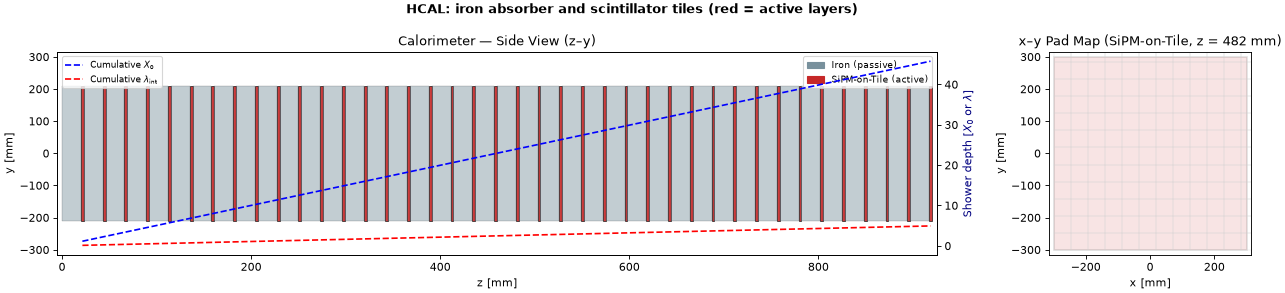

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(16, 3.8),
                          gridspec_kw={"width_ratios": [4, 1]})
hcal.plot_z(axes[0], show_depth=True)
hcal.plot_xy(axes[1])
fig.suptitle("HCAL: iron absorber and scintillator tiles (red = active layers)",
             fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

## Step 3 — ECAL Geometry

An electromagnetic calorimeter (ECAL) stops photons and electrons. Two designs are available:

- **Crystal ECAL**: lead tungstate (PbWO₄) crystals 230 mm long, about 26 $X_0$, as in the CMS
  experiment. The crystal is both absorber and active material, which gives a very small sampling
  term. A real crystal is read out as a whole. We cut it into 10 slices of 23 mm so that the
  filter has layers to step through.
- **Lead/scintillator sampling ECAL**: 66 pairs of 2 mm lead and 4 mm scintillator, about
  25 $X_0$ with $\sigma_s = 0.10$, as in the LHCb experiment.

In [5]:
# Crystal ECAL
crystal_layers = [CaloLayer("pwo", 23., is_active=True, cell_size_mm=22.)] * 10

# Lead/scintillator sampling ECAL
sampling_layers = []
for _ in range(66):
    sampling_layers.append(CaloLayer("pb",    2., is_active=False))
    sampling_layers.append(CaloLayer("scint", 4., is_active=True,
                                      cell_size_mm=40., sigma_sampling=0.10))

ecal_layers = crystal_layers   # switch to sampling_layers here
ecal = CalorimeterGeometry(ecal_layers, z_start=0., aperture_mm=200.)
print(ecal.summary())

CalorimeterGeometry
  Layers : 10 total, 10 active
  z range: 0 – 230 mm
  Depth  : 25.8 X₀,  1.15 λ_int
  X₀ eff : 8.9 mm/X₀   λ eff: 200.0 mm/λ
  Molière : 21.0 mm
  σ_s (EM): 0.028  σ_s (had): 0.50


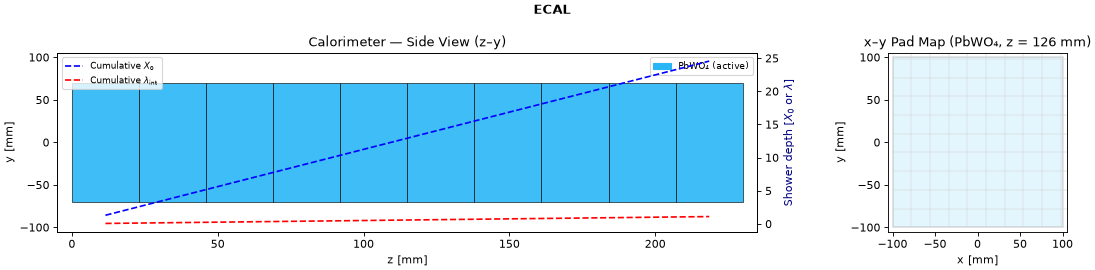

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.5),
                          gridspec_kw={"width_ratios": [3, 1]})
ecal.plot_z(axes[0], show_depth=True)
ecal.plot_xy(axes[1])
fig.suptitle("ECAL", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

## Step 4 — Combined ECAL + HCAL Side View

In a real detector the ECAL sits in front of the HCAL: photons stop in the ECAL, hadrons go
through it and shower in the HCAL. The dashed curves give the depth reached, in $X_0$ and in
$\lambda$.

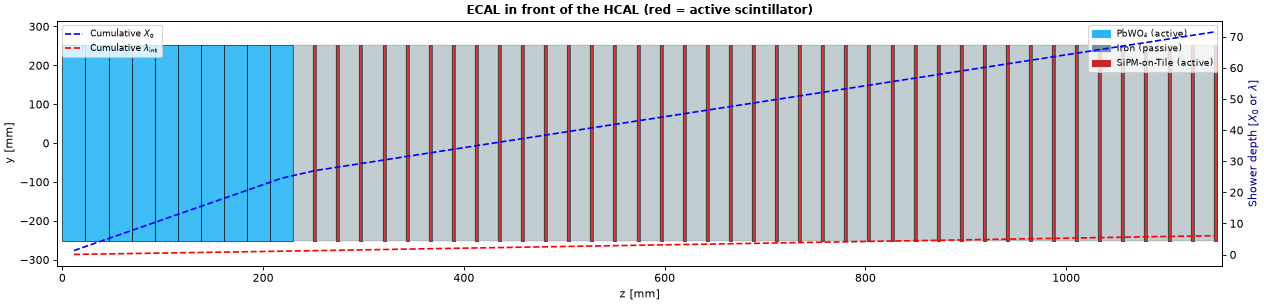

In [7]:
combined = CalorimeterGeometry(ecal_layers + hcal_layers, z_start=0., aperture_mm=600.)
fig, ax = plt.subplots(figsize=(16, 4))
combined.plot_z(ax, show_depth=True, height_frac=0.42)
ax.set_title("ECAL in front of the HCAL (red = active scintillator)", fontsize=11, fontweight="bold")
plt.tight_layout()
plt.show()

## Step 5 — EM Shower (Gamma): Simulation and Hit Projections

`CalorimeterSampler.sample()` simulates one shower and returns its **hits**: the energy collected
in each cell of each active layer.

Along the depth, the energy first rises as the shower multiplies, reaches a maximum, then dies
out. The share of each layer follows a known average curve, the shower profile. Across the layer,
the energy is spread around the shower axis with a width set by the Molière radius. Each layer's
energy then fluctuates according to the sampling term.

We send a 10 GeV photon that enters off-centre and at an angle.

In [8]:
E_gamma = 10.0  # [GeV]

x0_em, y0_em = 20., -15.    # entry position [mm]
tx_em, ty_em = 0.05, 0.03   # slopes dx/dz and dy/dz, 50 and 30 mrad

hits_em = CalorimeterSampler(ecal).sample(
    E_gamma, "gamma",
    x0=x0_em, y0=y0_em, tx=tx_em, ty=ty_em,
    seed=42)
print(f"{len(hits_em)} hits for a {E_gamma} GeV photon")
print(f"Total deposited energy: {sum(h['E'] for h in hits_em):.3f} GeV")

126 hits for a 10.0 GeV photon
Total deposited energy: 9.978 GeV


In [9]:
# One measurement per layer: the energy-weighted mean position of the hit cells
# and the energy of the layer. The model is built from the hits and the geometry.
em_model = CalorimeterElectromagneticModel.from_geometry(0, hits_em, ecal)
res_em = em_model.reconstruct()

z_first = min(h["z"] for h in hits_em)   # depth of the first layer [mm]
print("EM reconstruction (position given at the first layer):")
print(f"  E   = {res_em['E']:.2f} GeV    (true {E_gamma:.2f})")
print(f"  p_x = {res_em['x0']:+.1f} mm     (true {x0_em + tx_em * z_first:+.1f})")
print(f"  p_y = {res_em['y0']:+.1f} mm     (true {y0_em + ty_em * z_first:+.1f})")
print(f"  t_x = {1e3 * res_em['tx']:+.0f} mrad     (true {1e3 * tx_em:+.0f})")
print(f"  t_y = {1e3 * res_em['ty']:+.0f} mrad     (true {1e3 * ty_em:+.0f})")
print(f"  chi2/dof = {res_em['chi2_dof']:.2f}")

EM reconstruction (position given at the first layer):
  E   = 9.98 GeV    (true 10.00)
  p_x = +21.0 mm     (true +20.6)
  p_y = -14.3 mm     (true -14.7)
  t_x = +47 mrad     (true +50)
  t_y = +27 mrad     (true +30)
  chi2/dof = 0.24


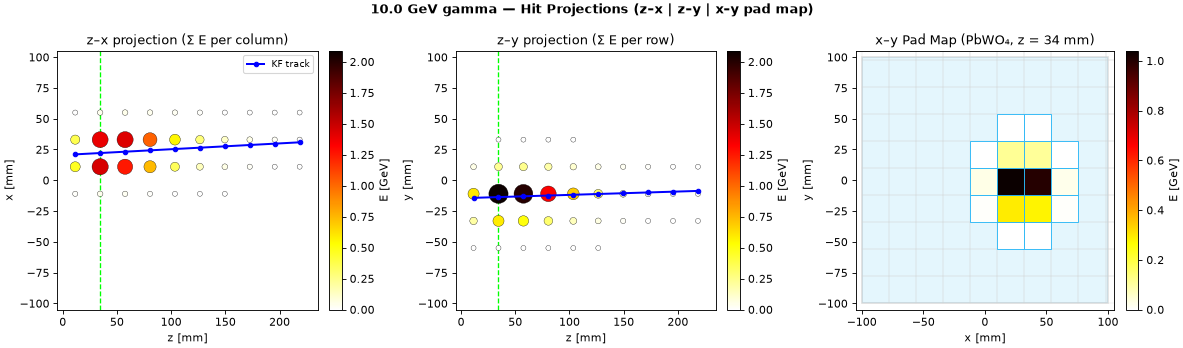

In [10]:
# Hits seen from the side (z-x and z-y) and from the front (x-y), with the filter's track
fig, axes = ecal.plot_hits_projections(
    hits_em,
    particle=f"{E_gamma} GeV gamma",
    smoothed_states=em_model.smoothed_states,
)
plt.show()

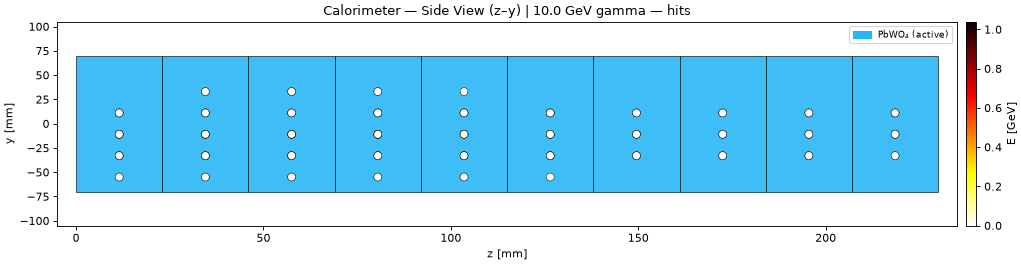

In [11]:
# Side view of the detector with the hits
fig, ax = plt.subplots(figsize=(13, 3.5))
ecal.plot_z(ax, show_depth=False, hits=hits_em, particle=f"{E_gamma} GeV gamma")
plt.tight_layout()
plt.show()

## Step 6 — Hadronic Shower (Neutral): Simulation and Hit Projections

A neutron showers through nuclear collisions, on the scale of $\lambda$ instead of $X_0$. Its
shower is longer and wider than an EM shower: here 90% of the energy stays within half an
interaction length of the axis.

The energy is also much less well measured. With $\sigma_s = 0.5$, a 10 GeV neutron is measured
to $0.5\sqrt{10} \approx 1.6$ GeV, so a single 10 GeV shower can easily read 7 or 13 GeV.

In [12]:
E_neutral = 10.0  # [GeV]

x0_had, y0_had = -10., 30.     # entry position [mm]
tx_had, ty_had = -0.02, 0.04   # slopes, -20 and 40 mrad

hits_had = CalorimeterSampler(hcal).sample(
    E_neutral, "neutral",
    x0=x0_had, y0=y0_had, tx=tx_had, ty=ty_had,
    seed=7)
print(f"{len(hits_had)} hits for a {E_neutral} GeV neutron")
print(f"Total deposited energy: {sum(h['E'] for h in hits_had):.2f} GeV")
print(f"Transverse spread of the shower (sigma): {hcal.hadronic_spread_mm:.1f} mm")

768 hits for a 10.0 GeV neutron
Total deposited energy: 7.60 GeV
Transverse spread of the shower (sigma): 43.5 mm


In [13]:
had_model = CalorimeterHadronicModel.from_geometry(0, hits_had, hcal)
res_h = had_model.reconstruct()

z_first = min(h["z"] for h in hits_had)
print("Hadronic reconstruction (position given at the first layer):")
print(f"  E   = {res_h['E']:.1f} GeV     (true {E_neutral:.1f}, expected spread {0.5 * np.sqrt(E_neutral):.1f})")
print(f"  p_x = {res_h['x0']:+.1f} mm     (true {x0_had + tx_had * z_first:+.1f})")
print(f"  p_y = {res_h['y0']:+.1f} mm     (true {y0_had + ty_had * z_first:+.1f})")
print(f"  t_x = {1e3 * res_h['tx']:+.0f} mrad     (true {1e3 * tx_had:+.0f})")
print(f"  t_y = {1e3 * res_h['ty']:+.0f} mrad     (true {1e3 * ty_had:+.0f})")
print(f"  chi2/dof = {res_h['chi2_dof']:.2f}")

Hadronic reconstruction (position given at the first layer):
  E   = 7.6 GeV     (true 10.0, expected spread 1.6)
  p_x = -10.5 mm     (true -10.4)
  p_y = +31.3 mm     (true +30.9)
  t_x = -19 mrad     (true -20)
  t_y = +38 mrad     (true +40)
  chi2/dof = 0.29


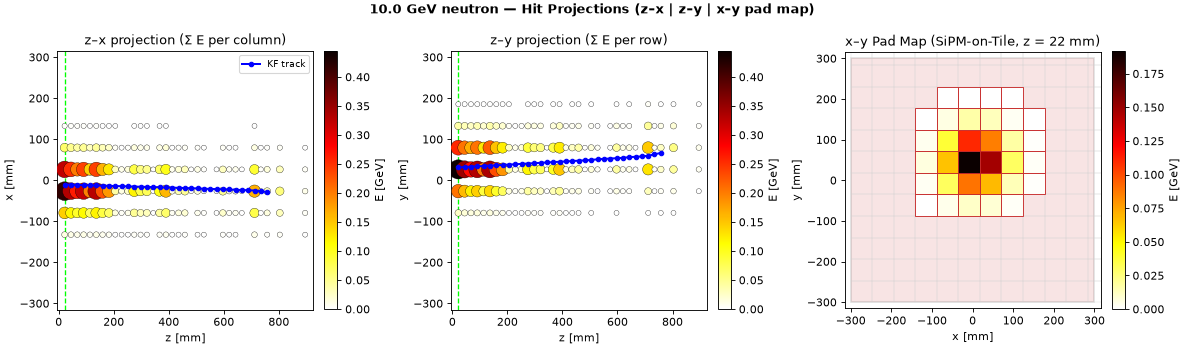

In [14]:
fig, axes = hcal.plot_hits_projections(
    hits_had,
    particle=f"{E_neutral} GeV neutron",
    smoothed_states=had_model.smoothed_states,
)
plt.show()

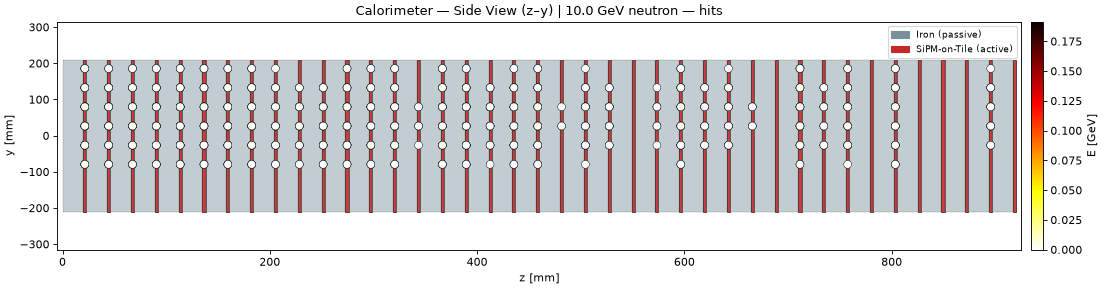

In [15]:
fig, ax = plt.subplots(figsize=(14, 3.8))
hcal.plot_z(ax, show_depth=False, hits=hits_had, particle=f"{E_neutral} GeV neutron")
plt.tight_layout()
plt.show()

## Step 7 — Resolution Study

The sampling term gives $\sigma_E/E = \sigma_s/\sqrt{E}$: the relative resolution improves as the
energy grows. A real detector also has a constant term $c$ (calibration errors, leakage) that
does not. The two add in quadrature, written $\oplus$:

$$\frac{\sigma_E}{E} = \frac{\sigma_s}{\sqrt{E}} \oplus c = \sqrt{\frac{\sigma_s^2}{E} + c^2}$$

The plots compare the sampling term of several designs with the targets used here for the ZDC:
$50\%/\sqrt{E} \oplus 5\%$ for the HCAL and $20\%/\sqrt{E} \oplus 3\%$ for the ECAL.

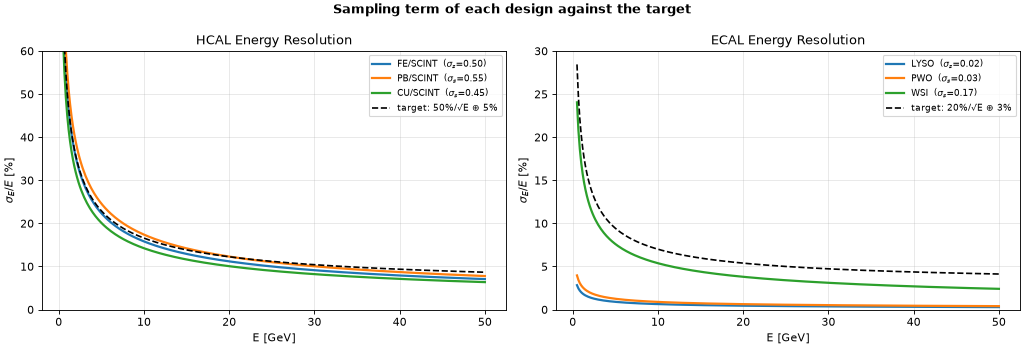

In [16]:
energies = np.linspace(0.5, 50., 300)

def resolution_pct(sigma_s, c, E):
    # sigma_E/E in percent: sampling term and constant term added in quadrature
    return 100 * np.sqrt(sigma_s ** 2 / E + c ** 2)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for ax, title, presets, target, ymax in [
    (axes[0], "HCAL Energy Resolution", HCAL_PRESETS, (0.50, 0.05), 60),
    (axes[1], "ECAL Energy Resolution", ECAL_PRESETS, (0.20, 0.03), 30),
]:
    for name, preset in presets.items():
        sigma_s = preset["sigma_sampling"]
        ax.plot(energies, resolution_pct(sigma_s, 0.0, energies), lw=2,
                label=f"{name.replace('_', '/').upper()}  ($\\sigma_s$={sigma_s:.2f})")
    ax.plot(energies, resolution_pct(*target, energies), "k--", lw=1.5,
            label=f"target: {100 * target[0]:.0f}%/√E ⊕ {100 * target[1]:.0f}%")
    ax.set_title(title)
    ax.set_xlabel("E [GeV]")
    ax.set_ylabel(r"$\sigma_E/E$ [%]")
    ax.set_ylim(0, ymax)
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

plt.suptitle("Sampling term of each design against the target", fontweight="bold")
plt.tight_layout()
plt.show()

## Step 8 — Monte Carlo Resolution Scan

One shower says little about the resolution. We simulate 100 showers at each of five energies,
reconstruct each one, and take the mean and the spread of the reconstructed energy.

The mean should equal the true energy, and the spread should follow $\sigma_s/\sqrt{E}$ with the
sampling term put into the simulation: 2.8% for the crystals (the value of the CMS crystals), 50% for the HCAL.

In [17]:
energies_scan = [2., 5., 10., 20., 50.]   # [GeV]
n_trials = 100

def reconstructed_energies(geometry, model_class, particle, E):
    energies = []
    for seed in range(n_trials):
        hits = CalorimeterSampler(geometry).sample(E, particle, seed=seed)
        if hits:
            energies.append(model_class.from_geometry(0, hits, geometry).reconstruct()["E"])
    return np.mean(energies), np.std(energies)

results_em, results_had = {}, {}
for E in energies_scan:
    results_em[E]  = reconstructed_energies(ecal, CalorimeterElectromagneticModel, "gamma", E)
    results_had[E] = reconstructed_energies(hcal, CalorimeterHadronicModel, "neutral", E)
    print(f"E = {E:4.0f} GeV | EM: {results_em[E][0]:6.2f} ± {results_em[E][1]:.2f} GeV"
          f"  | hadronic: {results_had[E][0]:6.2f} ± {results_had[E][1]:.2f} GeV")

E =    2 GeV | EM:   2.00 ± 0.04 GeV  | hadronic:   2.04 ± 0.69 GeV


E =    5 GeV | EM:   5.00 ± 0.07 GeV  | hadronic:   5.00 ± 1.07 GeV


E =   10 GeV | EM:  10.01 ± 0.09 GeV  | hadronic:   9.98 ± 1.49 GeV


E =   20 GeV | EM:  20.01 ± 0.13 GeV  | hadronic:  20.12 ± 2.05 GeV


E =   50 GeV | EM:  50.02 ± 0.20 GeV  | hadronic:  50.21 ± 3.34 GeV


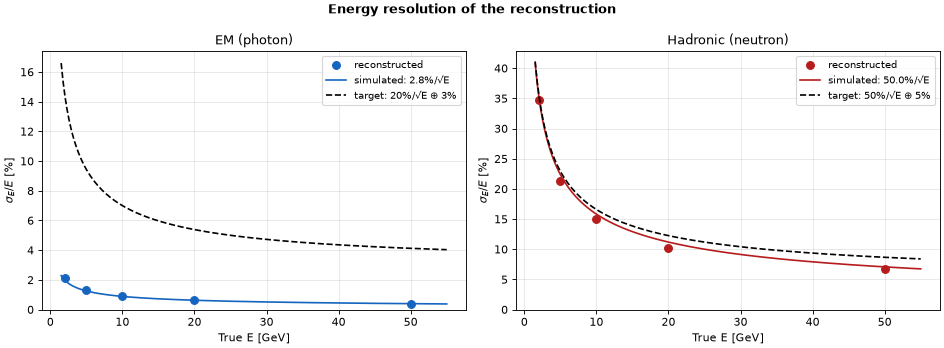

In [18]:
E_arr = np.array(energies_scan)
e_fine = np.linspace(1.5, 55., 200)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for ax, results, label, color, sigma_s, target in [
    (axes[0], results_em,  "EM (photon)",        "#1565C0", ecal.sigma_sampling_em,  (0.20, 0.03)),
    (axes[1], results_had, "Hadronic (neutron)", "#B71C1C", hcal.sigma_sampling_had, (0.50, 0.05)),
]:
    stds = np.array([results[E][1] for E in energies_scan])
    ax.plot(E_arr, stds / E_arr * 100, "o", color=color, ms=7, label="reconstructed")
    ax.plot(e_fine, resolution_pct(sigma_s, 0.0, e_fine), "-", color=color, lw=1.5,
            label=f"simulated: {100 * sigma_s:.1f}%/√E")
    ax.plot(e_fine, resolution_pct(*target, e_fine), "k--", lw=1.5,
            label=f"target: {100 * target[0]:.0f}%/√E ⊕ {100 * target[1]:.0f}%")
    ax.set_xlabel("True E [GeV]")
    ax.set_ylabel(r"$\sigma_E/E$ [%]")
    ax.set_title(label)
    ax.legend(fontsize=9)
    ax.grid(alpha=0.3)
    ax.set_ylim(0)

plt.suptitle("Energy resolution of the reconstruction", fontweight="bold")
plt.tight_layout()
plt.show()

## Step 9 — Custom Geometry (W/Si ECAL + Fe/SiPM-Tile HCAL)

Any stack of layers can be described the same way. This one puts a compact ECAL of tungsten
plates and silicon sensors in front of the HCAL of Step 2. Tungsten has a short $X_0$ and a small
Molière radius, so the ECAL is thin and its showers are narrow. The silicon samples only a small
part of the shower, hence a sampling term of about $17\%/\sqrt{E}$.

CalorimeterGeometry
  Layers : 60 total, 30 active
  z range: 0 – 114 mm
  Depth  : 30.1 X₀,  1.11 λ_int
  X₀ eff : 3.8 mm/X₀   λ eff: 102.4 mm/λ
  Molière : 9.9 mm
  σ_s (EM): 0.170  σ_s (had): 0.50


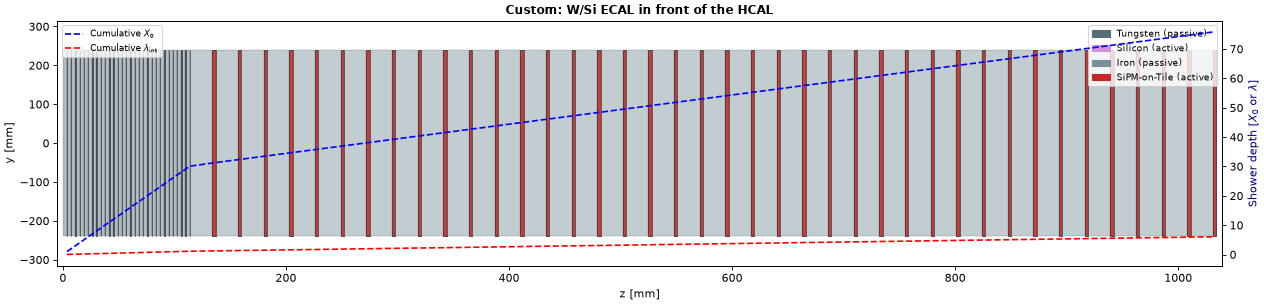

In [19]:
wsi_layers = []
for _ in range(30):
    wsi_layers.append(CaloLayer("w",   3.5, is_active=False))
    wsi_layers.append(CaloLayer("si",  0.3, is_active=True,
                                 cell_size_mm=5., sigma_sampling=0.17))

print(CalorimeterGeometry(wsi_layers).summary())   # the ECAL alone

custom = CalorimeterGeometry(wsi_layers + hcal_layers, z_start=0., aperture_mm=600.)
fig, ax = plt.subplots(figsize=(16, 4))
custom.plot_z(ax, show_depth=True, height_frac=0.40)
ax.set_title("Custom: W/Si ECAL in front of the HCAL", fontsize=11, fontweight="bold")
plt.tight_layout()
plt.show()